# Revisión independiente de vida temporal bajo IFRS 17

**Seguros Barú, S.A. (ficticia) · cierre al 31 de diciembre de 2025**

Este notebook muestra cómo reviso los cálculos de vida temporal de una aseguradora. Recibo los archivos que entrega la entidad, rehago cada cálculo de forma independiente y comparo mi resultado con las cifras que ella reporta. El recorrido cubre la proyección de flujos, el ajuste por riesgo, el valor presente de los flujos de cumplimiento, el CSM al reconocimiento inicial, las unidades de cobertura y la amortización del CSM. También cubre el pasivo por siniestros incurridos (LIC): siniestros pendientes, IBNR, gastos de liquidación, descuento y un ajuste por riesgo medido con bootstrap de Chain Ladder.

> **Aviso.** Proyecto personal con fines demostrativos. Seguros Barú es ficticia y todos los datos son sintéticos, generados con semilla fija y calibrados solo con fuentes públicas (tablas CSO 1980 de la SOA y curvas HQM del Tesoro de EE. UU.). Las cifras de la entidad contienen **errores sembrados a propósito** para el ejercicio. Nada de este documento constituye una opinión de auditoría, ni representa la metodología, las herramientas o la opinión de ningún empleador o cliente.

## 0. Enfoque de la revisión

La NIA 540 (Revisada), párr. 18, da tres formas de responder a los riesgos de una estimación contable: obtener evidencia de hechos ocurridos después del cierre, probar cómo la entidad hizo la estimación, o desarrollar una estimación propia. Este notebook usa las tres. La estimación propia es el centro: el código del revisor no reutiliza nada del modelo de la entidad, solo lee sus archivos (`data/audit_case/`), que genera `audit_case/entity_package.py`.

| Paso | IFRS 17 | Qué reviso | Sección |
|---|---|---|---|
| Datos | — | Integridad del censo y del registro de siniestros; completitud del listado de pendientes | 1 |
| Supuestos | 33, B37–B41, B72 | Mortalidad real contra esperada, caducidad, gastos y curva bloqueada | 2 |
| Flujos de cumplimiento | 33–36, B61–B71 | Proyección póliza por póliza dentro del límite del contrato | 3 |
| Ajuste por riesgo | 37, B86–B92, 119 | Costo de capital con mortalidad, caducidad y gastos | 4 |
| Agrupación y onerosidad | 14–24, 47 | Conjuntos, grupos y componente de pérdida | 5 |
| CSM | 38, 44, B72(b), B119 | Unidades de cobertura, acreción y liberación | 6 |
| LIC | 40(b), 36–37, B65(f) | Pendientes, IBNR (Chain Ladder y Bornhuetter-Ferguson), gastos, descuento y ajuste por riesgo con bootstrap | 7 |
| Conclusión | NIA 450 y 265 | Diferencias, su efecto y cómo se comunican | 8 |

In [1]:
import json
import warnings
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
CASE = ROOT / "data" / "audit_case"

plt.style.use("seaborn-v0_8-whitegrid")
warnings.filterwarnings("ignore", category=UserWarning)
COLORS = {"primary": "#1f4e79", "accent": "#c0504d", "grey": "#9e9e9e", "green": "#4f8a3c", "gold": "#d79b00"}
musd = FuncFormatter(lambda x, _: f"{x / 1e6:,.1f}M")


def money(df, extra=None, decimals=0):
    """Tabla con separador de miles; `extra` = formatos especiales por columna (solo presentación)."""
    fmt = {c: f"{{:,.{decimals}f}}" for c in df.select_dtypes("number").columns}
    fmt.update(extra or {})
    return df.style.format(fmt, na_rep="—")


def checkmark(ok):
    return "✔" if ok else "✘"

## 1. Datos que entrega la entidad

La entidad entrega cinco archivos: el censo de pólizas de las cohortes 2023 a 2025, el registro de siniestros reportados hasta el 31 de diciembre de 2025, los siniestros reportados entre el cierre y la fecha del informe (28 de febrero de 2026), su documento de supuestos y su paquete de cierre con las cifras que reporta. Las tablas CSO 1980 y las curvas de descuento son públicas y vienen del propio repositorio.

In [2]:
census = pd.read_csv(CASE / "census.csv", parse_dates=["issue_date", "exit_date"])
register = pd.read_csv(CASE / "claims_register.csv", parse_dates=["death_date", "report_date", "payment_date"])
after_close = pd.read_csv(CASE / "claims_after_close.csv", parse_dates=["death_date", "report_date"])
assumptions = json.loads((CASE / "assumptions.json").read_text(encoding="utf-8"))
mgmt = json.loads((CASE / "management_package.json").read_text(encoding="utf-8"))
cso = pd.read_csv(ROOT / "data/raw/mortality/cso1980_anb.csv", comment="#").set_index("age")

summary = pd.DataFrame({
    "pólizas": census.groupby("cohort").size(),
    "suma asegurada (USD)": census.groupby("cohort")["sum_insured"].sum(),
    "prima anual (USD)": census.groupby("cohort")["annual_premium"].sum(),
})
print(f"Siniestros reportados al 31-dic-2025: {len(register):,} | reportados después del cierre: {len(after_close):,}")
money(summary)

Siniestros reportados al 31-dic-2025: 475 | reportados después del cierre: 21


,pólizas,suma asegurada (USD),prima anual (USD)
cohort,,,
2023,"25,000","3,025,230,000","25,089,464"
2024,"25,000","3,017,735,000","24,884,194"
2025,"25,000","3,019,425,000","24,881,074"


### 1.1 Pruebas de integridad de datos

Antes de recalcular cualquier cosa, pruebo que los datos sean completos y coherentes entre sí. Si el censo o el registro de siniestros tienen errores, cualquier recálculo hereda el problema. Cada prueba se responde con todo el universo de registros, no con una muestra.

In [3]:
pol = census.set_index("policy_id")
reg = register.join(pol[["issue_date", "term", "sum_insured"]], on="policy_id")
cover_end = pd.to_datetime((reg["issue_date"].dt.year + reg["term"]).astype(str) + "-01-01")
paid = register["status"] == "pagado"

tests = pd.Series({
    "Identificador de póliza único en el censo": census["policy_id"].is_unique,
    "Cada siniestro tiene su póliza en el censo": register["policy_id"].isin(census["policy_id"]).all(),
    "La muerte ocurre dentro de la vigencia": ((reg["death_date"] >= reg["issue_date"]) & (reg["death_date"] < cover_end)).all(),
    "El reporte es posterior o igual a la muerte": (register["report_date"] >= register["death_date"]).all(),
    "El pago es posterior o igual al reporte": (register.loc[paid, "payment_date"] >= register.loc[paid, "report_date"]).all(),
    "Monto del siniestro = suma asegurada": (reg["amount"] == reg["sum_insured"]).all(),
    "Pólizas 'fallecida' en el censo = siniestros reportados":
        set(census.loc[census["exit"] == "fallecida", "policy_id"]) == set(register["policy_id"]),
}).map(checkmark).to_frame("resultado")
tests

,resultado
Identificador de póliza único en el censo,✔
Cada siniestro tiene su póliza en el censo,✔
La muerte ocurre dentro de la vigencia,✔
El reporte es posterior o igual a la muerte,✔
El pago es posterior o igual al reporte,✔
Monto del siniestro = suma asegurada,✔
Pólizas 'fallecida' en el censo = siniestros reportados,✔


### 1.2 Completitud del listado de siniestros pendientes

La entidad calcula su reserva de siniestros pendientes con un listado extraído de su sistema de siniestros. Lo concilio contra el registro completo al 31 de diciembre: todo siniestro reportado y no pagado a esa fecha debe estar en el listado.

In [4]:
pending = register[register["status"] == "pendiente"]
listed = set(mgmt["pending_claims_listing"])
missing = pending[~pending["claim_id"].isin(listed)]

print(f"Pendientes según el registro al 31-dic-2025: {len(pending):>3} siniestros, USD {pending['amount'].sum():>12,.0f}")
print(f"Pendientes en el listado de la entidad:       {len(listed):>3} siniestros, USD {mgmt['lic_2025']['rbns']:>12,.0f}")
print(f"No incluidos en el listado:                  {len(missing):>3} siniestros, USD {missing['amount'].sum():>12,.0f}")
missing[["claim_id", "policy_id", "death_date", "report_date", "amount"]]

Pendientes según el registro al 31-dic-2025:  40 siniestros, USD    5,035,000
Pendientes en el listado de la entidad:        34 siniestros, USD    4,240,000
No incluidos en el listado:                    6 siniestros, USD      795,000


,claim_id,policy_id,death_date,report_date,amount
456,SIN-00465,VT2023-10781,2025-11-09,2025-12-28,65000.0
469,SIN-00481,VT2024-08525,2025-12-01,2025-12-24,70000.0
470,SIN-00482,VT2023-18946,2025-12-02,2025-12-25,175000.0
472,SIN-00488,VT2025-18117,2025-12-10,2025-12-25,125000.0
473,SIN-00490,VT2024-13388,2025-12-15,2025-12-23,250000.0
474,SIN-00497,VT2025-04845,2025-12-23,2025-12-26,110000.0


**Hallazgo 5 (completitud).** Todos los siniestros que faltan se reportaron entre el 20 y el 31 de diciembre. El listado se extrajo el 19 de diciembre y no se actualizó al cierre. Además de corregir la cifra, esto es una deficiencia de control sobre el corte de información, que se comunica según la NIA 265.

## 2. Supuestos

La entidad declara sus supuestos en su documento de supuestos. Los implemento por mi cuenta, a partir del texto y no de su código, y pruebo el más importante, la mortalidad, contra la experiencia real.

- **Mortalidad (par. 33, B37–B41):** CSO 1980 por edad al cumpleaños más cercano (tablas 42 y 36 de la SOA) por un factor de mejor estimación según la edad alcanzada, con mejora de 1% anual desde 2025 (B58).
- **Caducidad:** 8%, 6% y 4% desde el tercer año póliza.
- **Gastos (B65):** suscripción de USD 150 por póliza nueva, mantenimiento de USD 60 por póliza y año, y USD 200 por siniestro, con inflación de 2,5%.
- **Descuento (par. 36, B72):** la curva HQM de la política del proyecto. Para la cohorte 2025, la curva bloqueada es la de diciembre de 2024; para el LIC al cierre se usa la de diciembre de 2025.

In [5]:
MORT = assumptions["mortality"]
BE = MORT["best_estimate_factor_by_attained_age"]
IMPROVEMENT = MORT["annual_improvement"]
LAPSE = np.array(assumptions["lapse_by_policy_year"])
EXP = assumptions["expenses"]
COMM = assumptions["commissions"]
T = 20  # plazo máximo en años


def cso_q(sex, age):
    age = np.minimum(np.asarray(age), cso.index.max())
    return np.where(np.asarray(sex) == "M", cso["qx_male"].to_numpy()[age], cso["qx_female"].to_numpy()[age])


def be_factor(age):
    age = np.asarray(age)
    return np.where(age < 40, BE["25-39"], np.where(age < 50, BE["40-49"], BE["50+"]))


def lapse_rate(policy_year):
    return LAPSE[np.minimum(np.asarray(policy_year), len(LAPSE) - 1)]


def load_curve(month):
    raw = pd.read_csv(ROOT / f"data/processed/discount_curves_monthly_{month}.csv", header=[0, 1], index_col=0)
    return raw[("high", "discount_factor")].astype(float)   # factor de descuento por mes


def annual_dfs(monthly, years=T + 1):
    return np.r_[1.0, monthly.loc[[12 * k for k in range(1, years + 1)]].to_numpy()]


DF_LOCKED = annual_dfs(load_curve("2024-12"))   # curva bloqueada de la cohorte 2025 (B72(b))
CURVE_2025 = load_curve("2025-12")               # curva corriente al cierre (LIC)

years = np.array([1, 5, 10, 20])
pd.DataFrame({"tasa spot anual bloqueada (dic-2024)": DF_LOCKED[years] ** (-1 / years) - 1,
              "tasa spot anual al cierre (dic-2025)": annual_dfs(CURVE_2025)[years] ** (-1 / years) - 1},
             index=pd.Index(years, name="plazo (años)")).style.format("{:.2%}")

,tasa spot anual bloqueada (dic-2024),tasa spot anual al cierre (dic-2025)
plazo (años),,
1,4.64%,3.88%
5,4.96%,4.30%
10,5.43%,5.02%
20,5.84%,5.84%


### 2.1 Mortalidad real contra esperada (A/E)

Comparo las muertes reales de cada año con las esperadas según la mejor estimación de la entidad, aplicada a las pólizas expuestas al inicio de cada año. Incluyo los siniestros reportados después del cierre, porque son muertes ocurridas en el periodo. La credibilidad de cada año sigue el criterio clásico de fluctuación limitada: 1.082 muertes dan credibilidad completa, porque con ese número el resultado queda dentro de ±5% del valor verdadero con 90% de probabilidad (Longley-Cook, 1962). Con Z = √(n / 1.082), el factor creíble es Z × A/E + (1 − Z) × 100%.

In [6]:
deaths = pd.concat([register[["policy_id", "death_date", "amount"]], after_close[["policy_id", "death_date", "amount"]]])


def exposed_at_start(year):
    """Pólizas en vigor al 1 de enero del año (las caducidades ocurren el 31 de diciembre)."""
    return census[(census["cohort"] <= year) & (census["cohort"] + census["term"] > year)
                  & ~(census["exit_date"] < pd.Timestamp(f"{year}-01-01"))]


rows = []
for year in (2023, 2024, 2025):
    p = exposed_at_start(year)
    att = p["issue_age"] + year - p["cohort"]
    q = cso_q(p["sex"], att) * be_factor(att) * (1 - IMPROVEMENT) ** (year - 2025)
    d = deaths[deaths["death_date"].dt.year == year]
    rows.append({"año": year, "expuestos": len(p), "muertes esperadas": q.sum(), "muertes reales": len(d),
                 "A/E por número": len(d) / q.sum(), "A/E por monto": d["amount"].sum() / (q * p["sum_insured"]).sum()})
ae = pd.DataFrame(rows).set_index("año")
ae.loc["2023–2025"] = [ae["expuestos"].sum(), ae["muertes esperadas"].sum(), ae["muertes reales"].sum(),
                       ae["muertes reales"].sum() / ae["muertes esperadas"].sum(), np.nan]
ae["Z"] = np.minimum(1, np.sqrt(ae["muertes reales"] / 1082))
ae["factor creíble"] = ae["Z"] * ae["A/E por número"] + (1 - ae["Z"])
z_poisson = (ae.loc["2023–2025", "muertes reales"] - ae.loc["2023–2025", "muertes esperadas"]) / np.sqrt(ae.loc["2023–2025", "muertes esperadas"])
print(f"Desviación del total respecto a lo esperado (Poisson): {z_poisson:.2f} desviaciones estándar")
ae.style.format({"expuestos": "{:,.0f}", "muertes esperadas": "{:,.1f}", "muertes reales": "{:,.0f}",
                 "A/E por número": "{:.1%}", "A/E por monto": "{:.1%}", "Z": "{:.0%}", "factor creíble": "{:.1%}"}, na_rep="—")

Desviación del total respecto a lo esperado (Poisson): 0.04 desviaciones estándar


,expuestos,muertes esperadas,muertes reales,A/E por número,A/E por monto,Z,factor creíble
año,,,,,,,
2023,"25,000",83.5,84,100.6%,102.2%,28%,100.2%
2024,"47,962",165.3,173,104.7%,98.0%,40%,101.9%
2025,"69,406",246.3,239,97.0%,100.4%,47%,98.6%
2023–2025,"142,368",495.2,496,100.2%,—,68%,100.1%


La mortalidad real de 2023 a 2025 coincide con la mejor estimación: el A/E acumulado es de 100% por número, y la desviación bajo un supuesto de Poisson es prácticamente nula. Ningún año se aleja más de unos 5 puntos, algo esperable con 80 a 250 muertes por año. Con 496 muertes la credibilidad es de 68%, y el factor creíble queda en 100%. El A/E por monto también queda cerca de 100%. La prueba respalda el supuesto de mortalidad de la entidad (B56–B57), así que lo uso sin cambios en el recálculo.

## 3. Proyección de flujos de cumplimiento (par. 33–35, B61–B71)

La función siguiente proyecta cada póliza año por año, en forma de matriz: filas = pólizas, columnas = años. Es la misma lógica de una hoja de cálculo actuarial, pero aplicada a 25.000 pólizas a la vez. El límite del contrato es el plazo completo, porque la prima nivelada está garantizada y la entidad no puede reevaluar el riesgo de cada asegurado (par. 34). Las primas, comisiones y gastos ocurren al inicio del año, y las muertes y sus gastos al final.

In [7]:
def project(pol, dfs, mort=1.0, lapse=1.0, expense=1.0, infl_add=0.0, start=0):
    """Proyección anual póliza por póliza. `start` = años póliza ya transcurridos."""
    t = np.arange(T)
    dur = start + t                                            # año póliza (0 = primer año)
    cal = pol["cohort"].to_numpy()[:, None] + dur - 2025       # años desde 2025
    age = pol["issue_age"].to_numpy()[:, None] + dur
    on = dur < pol["term"].to_numpy()[:, None]                 # límite del contrato (par. 34)

    q = cso_q(pol["sex"].to_numpy()[:, None], age) * be_factor(age) * (1 - IMPROVEMENT) ** cal * mort
    q = np.where(on, np.minimum(q, 1.0), 0.0)
    w = np.where(on, np.minimum(lapse_rate(dur) * lapse, 1.0), 0.0)
    l = np.cumprod(np.hstack([np.ones((len(pol), 1)), ((1 - q) * (1 - w))[:, :-1]]), axis=1) * on

    G = pol["annual_premium"].to_numpy()[:, None]
    S = pol["sum_insured"].to_numpy()[:, None]
    c1 = pol["channel"].map(lambda c: COMM[c]["first_year"]).to_numpy()[:, None]
    cr = pol["channel"].map(lambda c: COMM[c]["renewal"]).to_numpy()[:, None]
    infl = (1 + EXP["inflation"] + infl_add) ** cal

    cf = SimpleNamespace(
        premiums=l * G,
        commissions=l * G * np.where(dur == 0, c1, cr),
        underwriting=l * np.where(dur == 0, EXP["underwriting_cost_per_new_policy"], 0.0),
        maintenance=l * EXP["maintenance_per_policy_year"] * infl * expense,
        claims=l * q * S,
        claim_handling=l * q * EXP["claim_handling_per_claim"] * infl * expense,
    )
    start_out = cf.commissions + cf.underwriting + cf.maintenance   # al inicio del año
    end_out = cf.claims + cf.claim_handling                          # al final del año
    pv_in = (cf.premiums * dfs[:T]).sum(1)
    pv_out = (start_out * dfs[:T]).sum(1) + (end_out * dfs[1:T + 1]).sum(1)
    return SimpleNamespace(**vars(cf), q=q, w=w, l=l, pv_in=pv_in, pv_out=pv_out,
                           fcf=pv_out - pv_in,        # flujos de cumplimiento sin RA (+ = salida neta)
                           cu=l * S)                  # suma asegurada en vigor esperada (B119)


c25 = census[census["cohort"] == 2025].reset_index(drop=True)
base = project(c25, DF_LOCKED)

### 3.1 Una póliza, como en la hoja de cálculo

Para que el cálculo se pueda seguir a mano, muestro una sola póliza con todas sus columnas. Es la misma tabla que armaría en Excel para revisar una muestra de pólizas. La primera línea impresa comprueba que la suma de la columna de valor presente coincide con el resultado vectorizado. La misma póliza está en `excel/Revision_VT_poliza_modelo.xlsx` con fórmulas vivas; su hoja `Conciliacion` compara cada cifra con este notebook.

In [8]:
i = c25.index[(c25["channel"] == "agentes") & (c25["sex"] == "M") & (c25["issue_age"] == 45)
              & (c25["term"] == 20) & (c25["sum_insured"] == 150_000)][0]
p = c25.loc[i]
yrs = np.arange(p["term"])
sheet = pd.DataFrame({
    "año": yrs + 1, "edad": p["issue_age"] + yrs, "q": base.q[i, yrs], "caducidad": base.w[i, yrs],
    "en vigor": base.l[i, yrs], "prima": base.premiums[i, yrs], "comisión": base.commissions[i, yrs],
    "gastos": base.underwriting[i, yrs] + base.maintenance[i, yrs],
    "siniestros": base.claims[i, yrs], "gasto siniestro": base.claim_handling[i, yrs],
    "FD inicio": DF_LOCKED[yrs], "FD fin": DF_LOCKED[yrs + 1],
})
sheet["VP neto"] = ((sheet["comisión"] + sheet["gastos"] - sheet["prima"]) * sheet["FD inicio"]
                    + (sheet["siniestros"] + sheet["gasto siniestro"]) * sheet["FD fin"])
print(f"Póliza {p['policy_id']}: {p['sex']}, {p['issue_age']} años, plazo {p['term']}, "
      f"suma asegurada USD {p['sum_insured']:,.0f}, prima anual USD {p['annual_premium']:,.2f}")
print(f"Suma de la columna 'VP neto': {sheet['VP neto'].sum():,.2f} | resultado vectorizado: {base.fcf[i]:,.2f}")
sheet.style.format({"q": "{:.5f}", "caducidad": "{:.0%}", "en vigor": "{:.4f}", "FD inicio": "{:.4f}", "FD fin": "{:.4f}",
                    **{c: "{:,.2f}" for c in ["prima", "comisión", "gastos", "siniestros", "gasto siniestro", "VP neto"]}}).hide()

Póliza VT2025-05533: M, 45 años, plazo 20, suma asegurada USD 150,000, prima anual USD 1,793.78
Suma de la columna 'VP neto': -4,757.04 | resultado vectorizado: -4,757.04


año,edad,q,caducidad,en vigor,prima,comisión,gastos,siniestros,gasto siniestro,FD inicio,FD fin,VP neto
1,45,0.00341,8%,1.0000,"1,793.78",896.89,210.00,511.88,0.68,1.0000,0.9556,-197.07
2,46,0.00365,6%,0.9169,"1,644.65",82.23,56.39,502.41,0.69,0.9556,0.9122,-980.30
3,47,0.00391,4%,0.8587,"1,540.32",77.02,54.13,503.70,0.71,0.9122,0.8691,-846.99
4,48,0.00418,4%,0.8211,"1,472.92",73.65,53.06,514.50,0.74,0.8691,0.8269,-744.03
5,49,0.00447,4%,0.7850,"1,408.10",70.41,51.99,526.80,0.78,0.8269,0.7850,-648.94
6,50,0.00606,4%,0.7502,"1,345.73",67.29,50.93,682.18,1.03,0.7850,0.7436,-455.62
7,51,0.00653,4%,0.7158,"1,284.07",64.20,49.81,701.08,1.08,0.7436,0.7029,-376.44
8,52,0.00705,4%,0.6827,"1,224.66",61.23,48.69,721.80,1.14,0.7029,0.6637,-303.73
9,53,0.00764,4%,0.6508,"1,167.38",58.37,47.58,745.35,1.21,0.6637,0.6256,-237.44
10,54,0.00830,4%,0.6200,"1,112.13",55.61,46.46,771.57,1.28,0.6256,0.5892,-176.52


### 3.2 Flujos de la cohorte 2025 y su valor presente

El valor presente de los flujos de cumplimiento (PVFCF) es salidas menos entradas. Un valor negativo significa que la entidad espera recibir más de lo que paga.

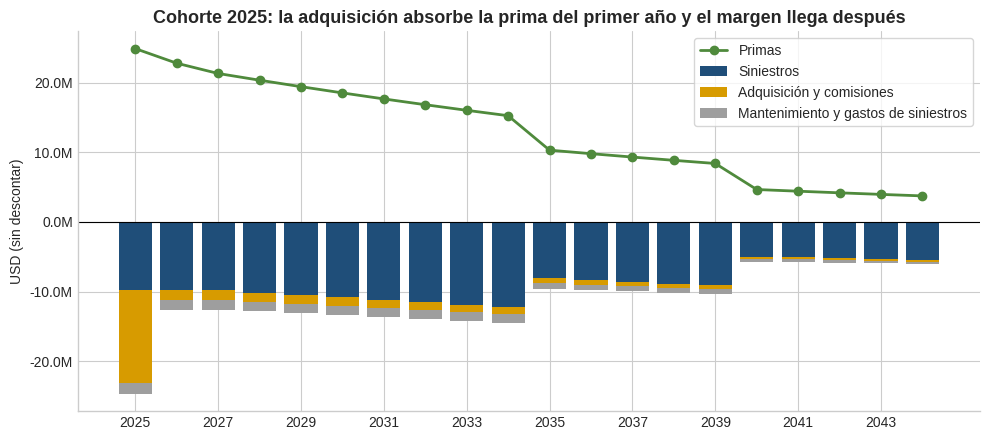

Control: PVFCF por póliza sumado = -42,344,316


,USD
VP primas,"-192,232,041"
VP comisiones y suscripción,"24,267,158"
VP mantenimiento,"13,296,041"
VP siniestros,"112,103,115"
VP gastos de siniestros,"221,411"
PVFCF (salidas − entradas),"-42,344,316"


In [9]:
flows = pd.DataFrame({k: getattr(base, k).sum(0) for k in
                      ["premiums", "commissions", "underwriting", "maintenance", "claims", "claim_handling"]},
                     index=pd.Index(2025 + np.arange(T), name="año"))

fig, ax = plt.subplots(figsize=(10, 4.5))
x = flows.index
ax.bar(x, -flows["claims"], color=COLORS["primary"], label="Siniestros")
ax.bar(x, -(flows["commissions"] + flows["underwriting"]), bottom=-flows["claims"], color=COLORS["gold"], label="Adquisición y comisiones")
ax.bar(x, -(flows["maintenance"] + flows["claim_handling"]),
       bottom=-(flows["claims"] + flows["commissions"] + flows["underwriting"]), color=COLORS["grey"], label="Mantenimiento y gastos de siniestros")
ax.plot(x, flows["premiums"], color=COLORS["green"], marker="o", lw=2, label="Primas")
ax.axhline(0, color="black", lw=0.8)
ax.yaxis.set_major_formatter(musd)
ax.set_title("Cohorte 2025: la adquisición absorbe la prima del primer año y el margen llega después", fontsize=13, fontweight="bold")
ax.set_xticks(range(2025, 2045, 2))
ax.set_ylabel("USD (sin descontar)")
ax.legend(loc="upper right", frameon=True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

pv = pd.Series({
    "VP primas": -(flows["premiums"].to_numpy() * DF_LOCKED[:T]).sum(),
    "VP comisiones y suscripción": ((flows["commissions"] + flows["underwriting"]).to_numpy() * DF_LOCKED[:T]).sum(),
    "VP mantenimiento": (flows["maintenance"].to_numpy() * DF_LOCKED[:T]).sum(),
    "VP siniestros": (flows["claims"].to_numpy() * DF_LOCKED[1:T + 1]).sum(),
    "VP gastos de siniestros": (flows["claim_handling"].to_numpy() * DF_LOCKED[1:T + 1]).sum(),
})
pv["PVFCF (salidas − entradas)"] = pv.sum()
print(f"Control: PVFCF por póliza sumado = {base.fcf.sum():,.0f}")
money(pv.to_frame("USD"))

## 4. Ajuste por riesgo no financiero (par. 37, B86–B92)

La política de la entidad es el costo de capital de 6%. El capital es el efecto, en los flujos de cumplimiento, de tres choques permanentes inspirados en la fórmula estándar de Solvencia II (Reglamento Delegado (UE) 2015/35, art. 137, 140 y 142): mortalidad +15%, caducidad ±50% (el peor sentido) y gastos +10% con inflación +1 punto. Los tres se agregan con una matriz de correlación, y el capital se proyecta en proporción a la suma asegurada en vigor esperada:

$$RA = 6\% \times \sum_{t} Capital_0 \cdot \frac{SA_t}{SA_0} \cdot FD_{t+1}$$

El ajuste refleja la diversificación dentro de la cartera (B88(a)). Lo calculo para toda la cohorte y lo asigno a cada celda en proporción a su capital individual, para poder clasificar las celdas en el paso siguiente. B86 es explícito: el ajuste cubre el riesgo de seguro y también otros riesgos no financieros, como la caducidad y los gastos.

In [10]:
COC = assumptions["risk_adjustment_policy"]["coc_rate"]
CORR = np.array([[1.0, 0.0, 0.25],    # mortalidad, caducidad, gastos
                 [0.0, 1.0, 0.50],
                 [0.25, 0.50, 1.0]])

band = pd.cut(c25["issue_age"], [24, 39, 49, 60], labels=["25-39", "40-49", "50-60"]).astype(str)
c25["cell"] = c25["channel"] + "|T" + c25["term"].astype(str) + "|" + band     # celda (par. 17)

delta = pd.DataFrame({
    "mortality": project(c25, DF_LOCKED, mort=1.15).fcf - base.fcf,
    "lapse_up": project(c25, DF_LOCKED, lapse=1.5).fcf - base.fcf,
    "lapse_down": project(c25, DF_LOCKED, lapse=0.5).fcf - base.fcf,
    "expense": project(c25, DF_LOCKED, expense=1.10, infl_add=0.01).fcf - base.fcf,
})
tot = delta.sum()
lapse_dir = "lapse_up" if tot["lapse_up"] >= tot["lapse_down"] else "lapse_down"


def capital(d):
    v = np.maximum(np.array([d["mortality"], d[lapse_dir], d["expense"]]), 0.0)
    return float(np.sqrt(v @ CORR @ v))


cap_total = capital(tot)
by_cell = delta.groupby(c25["cell"]).sum()
standalone = by_cell.apply(capital, axis=1)
alloc = cap_total * standalone / standalone.sum()

cu_cell = pd.DataFrame(base.cu).groupby(c25["cell"]).sum()
runoff = (cu_cell.to_numpy() * DF_LOCKED[1:T + 1]).sum(1) / cu_cell[0].to_numpy()
ra_cell = pd.Series(COC * alloc.to_numpy() * runoff, index=cu_cell.index)
# Cada póliza recibe el ajuste de su celda en proporción a su suma asegurada (solo para agregar).
c25["ra_aud"] = ra_cell.reindex(c25["cell"]).to_numpy() * c25["sum_insured"] / c25.groupby("cell")["sum_insured"].transform("sum")

z995 = norm.ppf(0.995)
ra_total = c25["ra_aud"].sum()
conf = norm.cdf(ra_total / (cap_total / z995))
caps = pd.Series({"Δ mortalidad +15%": tot["mortality"], f"Δ caducidad {'+' if lapse_dir == 'lapse_up' else '−'}50% (peor)": tot[lapse_dir],
                  "Δ gastos +10% e inflación +1 pp": tot["expense"], "Suma sin diversificar": standalone.sum(),
                  "Capital diversificado (t = 0)": cap_total, "Ajuste por riesgo de la cohorte": ra_total})
print(f"Nivel de confianza equivalente (par. 119), aproximación normal con σ = capital / z(99,5%): {conf:.0%}")
money(caps.to_frame("USD"))

Nivel de confianza equivalente (par. 119), aproximación normal con σ = capital / z(99,5%): 87%


,USD
Δ mortalidad +15%,"16,721,910"
Δ caducidad +50% (peor),"3,455,129"
Δ gastos +10% e inflación +1 pp,"2,224,233"
Suma sin diversificar,"18,361,126"
Capital diversificado (t = 0),"17,966,334"
Ajuste por riesgo de la cohorte,"7,986,260"


El nivel de confianza equivalente se revela según el par. 119. Aquí se aproxima con una distribución normal cuya desviación se deduce del capital al 99,5%, el mismo criterio del memo de política contable. Es una aproximación: el capital es a un año y el ajuste cubre toda la vida del contrato. Una revisión más profunda lo contrastaría con una simulación estocástica de los flujos.

### 4.1 ¿Es razonable la tasa de 6%?

La tasa viene de la política de la entidad, que la tomó de la fórmula estándar de Solvencia II (Reglamento Delegado (UE) 2015/35, art. 39). Esa referencia, sola, es un sustento débil, por tres razones.

- **IFRS 17 no fija la técnica ni la tasa (B91–B92).** El ajuste es la compensación que *esta* entidad exige por soportar el riesgo (B87) y refleja su propia aversión al riesgo (B88(b)). La tasa debería salir de su costo de capital: el rendimiento que exige al capital por encima del que ese capital gana invertido, el mismo que usa para tarificar y para planear su capital.
- **La referencia regulatoria cambió.** La revisión de Solvencia II bajó la tasa a 4,75% (Directiva (UE) 2025/2, con el Reglamento Delegado modificado aplicable desde enero de 2027), y Solvencia UK usa 4%. En los estados financieros de 2023, las aseguradoras que usaban costo de capital para IFRS 17 revelaron tasas de 4% a 6% (EY, 2024).
- **El resultado tiene que tener sentido.** B92 pide una revelación que permita comparar entidades. En la muestra de EY, el nivel de confianza más común fue de 70% a 79%.

La prueba es de sensibilidad: recalculo el ajuste y su nivel de confianza con distintas tasas. El ajuste es lineal en la tasa, así que basta reescalarlo.

In [11]:
duration = ra_total / (COC * cap_total)       # suma descontada del capital proyectado / capital inicial
rates = pd.Series([0.04, 0.0475, 0.05, 0.06, 0.08], name="tasa de costo de capital")
sens_coc = pd.DataFrame({"ajuste por riesgo": rates.to_numpy() * duration * cap_total}, index=rates)
sens_coc["nivel de confianza (aprox.)"] = norm.cdf(sens_coc["ajuste por riesgo"] / (cap_total / z995))
sens_coc["CSM menos componente de pérdida"] = -(base.fcf.sum() + sens_coc["ajuste por riesgo"])
print(f"Duración del capital: {duration:.2f} años | nivel de confianza = Φ(tasa × {duration:.2f} × {z995:.3f})")
money(sens_coc.rename(index=lambda r: f"{r:.2%}"), extra={"nivel de confianza (aprox.)": "{:.1%}"})

Duración del capital: 7.41 años | nivel de confianza = Φ(tasa × 7.41 × 2.576)


,ajuste por riesgo,nivel de confianza (aprox.),CSM menos componente de pérdida
tasa de costo de capital,,,
4.00%,"5,324,173",77.7%,"37,020,142"
4.75%,"6,322,456",81.8%,"36,021,860"
5.00%,"6,655,216",83.0%,"35,689,099"
6.00%,"7,986,260",87.4%,"34,358,056"
8.00%,"10,648,346",93.7%,"31,695,969"


Hay dos lecturas.

- **El nivel es alto.** Con 6%, el nivel implícito (87%) queda en la parte alta de lo observado en el mercado. Si la entidad usa además un percentil 75 para daños, como el motor principal de este proyecto, la diferencia entre carteras necesita una explicación: una entidad tiene una sola aversión al riesgo (B88(b)). Con 4,75%, el nivel bajaría a alrededor de 82%.
- **La aproximación tiene un límite.** Con este método, el nivel de confianza no depende del tamaño del riesgo. El ajuste y la desviación son proporcionales al mismo capital, así que el cociente solo depende de la tasa y de la duración del capital. El resultado sirve de referencia, pero no sustituye una distribución de los flujos, por ejemplo simulando mortalidad y caducidad. La conversión con una normal está descrita en el *Financial Reporter* de la SOA (Reback, 2017).

Para la revisión, la tasa no es un error. Es un juicio que la entidad debe sustentar con su propio costo de capital, aplicar de forma coherente entre carteras y revelar con su nivel de confianza (par. 117(c)(ii) y 119). Lo registro como punto a discutir con la entidad, no como hallazgo.

## 5. Agregación y onerosidad al reconocimiento inicial (par. 14–24, 47)

La cartera es vida temporal y la cohorte es anual (par. 22). Dentro de la cohorte, cada contrato va a uno de tres grupos (par. 16): oneroso al reconocimiento inicial (ONE), sin posibilidad significativa de volverse oneroso (SIG) o el resto (RES). El par. 17 permite clasificar por conjuntos de contratos en lugar de póliza por póliza, solo si hay información razonable y sustentable de que todos los contratos del conjunto caerán en el mismo grupo.

La entidad usó el canal de venta como conjunto. Yo evalúo por celda (canal × plazo × banda de edad), que es el nivel al que la tarifa y la experiencia de mortalidad cambian. Para SIG uso el estrés de la política: mortalidad +15%, caducidad ±30% en el sentido adverso y gastos +10% (par. 16(b), 19).

In [12]:
for name, lapse in (("up", 1.3), ("down", 0.7)):
    c25[f"fcf_stress_{name}"] = project(c25, DF_LOCKED, mort=1.15, lapse=lapse, expense=1.10).fcf
c25["pv_in"], c25["pv_out"], c25["fcf"] = base.pv_in, base.pv_out, base.fcf

# Réplica del ajuste de la entidad: solo choque de mortalidad, sin agregación (para conciliar).
runoff_pol = (base.cu * DF_LOCKED[1:T + 1]).sum(1) / base.cu[:, 0]
c25["ra_mgmt"] = COC * delta["mortality"].to_numpy() * runoff_pol


def classify(df, set_col, ra_col):
    s = df.groupby(set_col).agg(fcf=("fcf", "sum"), up=("fcf_stress_up", "sum"),
                                down=("fcf_stress_down", "sum"), ra=(ra_col, "sum"))
    s["FCF + RA"] = s["fcf"] + s["ra"]
    s["FCF + RA con estrés"] = np.maximum(s["up"], s["down"]) + s["ra"]
    s["grupo"] = np.select([s["FCF + RA"] > 0, s["FCF + RA con estrés"] <= 0], ["ONE", "SIG"], "RES")
    return s


def measure(df, group_col, ra_col):
    g = df.groupby(group_col).agg(pólizas=("policy_id", "size"), VP_entradas=("pv_in", "sum"),
                                  VP_salidas=("pv_out", "sum"), RA=(ra_col, "sum"))
    net = g["VP_salidas"] - g["VP_entradas"] + g["RA"]
    g["CSM"] = np.maximum(0.0, -net)                      # par. 38
    g["componente_pérdida"] = np.maximum(0.0, net)        # par. 47
    return g


cells = classify(c25, "cell", "ra_aud")
c25["group"] = "VT-2025-" + c25["cell"].map(cells["grupo"])
money(cells[["FCF + RA", "FCF + RA con estrés", "grupo"]].sort_values("FCF + RA", ascending=False).head(8))

,FCF + RA,FCF + RA con estrés,grupo
cell,,,
promo|T10|50-60,"644,612","1,573,712",ONE
promo|T15|50-60,"266,154","1,065,550",ONE
promo|T10|25-39,"-56,451","4,531",RES
promo|T10|40-49,"-62,309","232,913",RES
promo|T20|50-60,"-63,880","559,233",RES
promo|T15|25-39,"-98,339","-4,181",SIG
promo|T15|40-49,"-186,191","251,374",RES
promo|T20|25-39,"-222,757","-53,014",SIG


La tabla muestra las ocho celdas con menor margen. Las celdas onerosas son del canal promocional en edades de 50 a 60 años: tienen el descuento comercial de 20% y la mortalidad de mejor estimación más alta (95% de CSO 1980). Dentro del canal promocional completo, ese déficit queda compensado por las celdas jóvenes, que sí son rentables. Eso es justo lo que el par. 16 busca evitar: que las pérdidas de contratos onerosos se compensen con las ganancias de otros contratos.

### 5.1 Conciliación con la entidad

Primero repito el cálculo con las decisiones de la entidad (conjuntos por canal y ajuste solo por mortalidad) para comprobar que entiendo su número. Después corrijo un error a la vez, para atribuir cada parte de la diferencia a su causa.

In [13]:
def totals(g):
    return pd.Series({"Ajuste por riesgo": g["RA"].sum(), "CSM": g["CSM"].sum(), "Componente de pérdida": g["componente_pérdida"].sum()})


reported = pd.DataFrame(mgmt["cohort_2025_initial_recognition"]).T
rep = pd.Series({"Ajuste por riesgo": reported["risk_adjustment"].sum(), "CSM": reported["csm"].sum(),
                 "Componente de pérdida": reported["loss_component"].sum()})

sets_m = classify(c25, "channel", "ra_mgmt")
c25["group_mgmt"] = "VT-2025-" + c25["channel"].map(sets_m["grupo"])
step1 = totals(measure(c25, "group_mgmt", "ra_mgmt"))

cells_m = classify(c25, "cell", "ra_mgmt")
step2 = totals(measure(c25.assign(g=c25["cell"].map(cells_m["grupo"])), "g", "ra_mgmt"))
groups_aud = measure(c25, "group", "ra_aud")
step3 = totals(groups_aud)

recon = pd.DataFrame({"Reportado por la entidad": rep, "Réplica del revisor": step1,
                      "(a) Agrupación por celda (par. 16–17)": step2 - step1,
                      "(b) Ajuste con caducidad y gastos (B86)": step3 - step2, "Recálculo del revisor": step3})
print("Conjuntos de la entidad:", mgmt["sets_classification"], "| réplica:", sets_m["grupo"].to_dict())
money(recon)

Conjuntos de la entidad: {'agentes': 'SIG', 'bancaseguros': 'SIG', 'promo': 'RES'} | réplica: {'agentes': 'SIG', 'bancaseguros': 'SIG', 'promo': 'RES'}


,Reportado por la entidad,Réplica del revisor,(a) Agrupación por celda (par. 16–17),(b) Ajuste con caducidad y gastos (B86),Recálculo del revisor
Ajuste por riesgo,"7,386,742","7,386,742",0,"599,518","7,986,260"
CSM,"34,957,574","34,957,574","911,955","-600,707","35,268,822"
Componente de pérdida,0,0,"911,955","-1,189","910,766"


In [14]:
money(groups_aud)

,pólizas,VP_entradas,VP_salidas,RA,CSM,componente_pérdida
group,,,,,,
VT-2025-ONE,970,"10,672,808","11,030,680","552,893",0,"910,766"
VT-2025-RES,"3,465","30,089,710","26,687,230","1,329,856","2,072,624",0
VT-2025-SIG,"20,565","151,469,523","112,169,815","6,103,511","33,196,198",0


**Hallazgos 1 y 2.** La réplica coincide con la cifra reportada, así que las diferencias vienen de decisiones de método y no de datos.

- **Agrupación.** La evaluación por canal oculta contratos onerosos. Al separarlos, nace un grupo VT-2025-ONE con un componente de pérdida que debe ir al resultado de 2025 (par. 47). El CSM de los demás grupos sube, porque ya no absorbe ese déficit.
- **Ajuste por riesgo.** El cálculo de la entidad solo incluye el choque de mortalidad. Su propia política, y B86, piden incluir caducidad y gastos. El ajuste reportado está subestimado y el CSM sobrestimado en el mismo monto.

## 6. Unidades de cobertura y amortización del CSM (par. 44, B72(b), B119)

Las unidades de cobertura miden el servicio de cada periodo. En vida temporal son la suma asegurada en vigor esperada, sin descontar, según la política. Al cierre de cada periodo el CSM, ya con sus intereses, se reparte en partes iguales entre las unidades del periodo y las futuras (B119(b)). Los intereses se acreditan con las tasas bloqueadas al reconocimiento inicial (par. 44(b), B72(b)), es decir, con las tasas forward implícitas de la curva de diciembre de 2024.

In [15]:
fwd = DF_LOCKED[:-1] / DF_LOCKED[1:] - 1                       # forwards a 1 año de la curva bloqueada
cu_group = pd.DataFrame(base.cu).groupby(c25["group"]).sum()   # unidades de cobertura esperadas por año


def csm_schedule(csm0, cu, rates):
    out, opening = [], csm0
    for t in range(len(cu)):
        remaining = cu[t:].sum()
        if remaining <= 0:
            break
        interest = opening * rates[t]
        release = (opening + interest) * cu[t] / remaining
        out.append((2025 + t, opening, interest, -release, opening + interest - release, cu[t] / remaining))
        opening += interest - release
    return pd.DataFrame(out, columns=["año", "saldo inicial", "intereses", "liberación", "saldo final", "% liberado"]).set_index("año")


sched = {g: csm_schedule(groups_aud.loc[g, "CSM"], cu_group.loc[g].to_numpy(), fwd)
         for g in groups_aud.index if groups_aud.loc[g, "CSM"] > 0}
big = groups_aud["CSM"].idxmax()
print(f"Amortización esperada del CSM de {big} (primeros 6 años):")
money(sched[big].head(6), extra={"% liberado": "{:.1%}"})

Amortización esperada del CSM de VT-2025-SIG (primeros 6 años):


,saldo inicial,intereses,liberación,saldo final,% liberado
año,,,,,
2025,"33,196,198","1,541,190","-3,231,072","31,506,316",9.3%
2026,"31,506,316","1,501,427","-3,106,045","29,901,697",9.4%
2027,"29,901,697","1,480,097","-3,055,482","28,326,313",9.7%
2028,"28,326,313","1,448,593","-3,073,771","26,701,135",10.3%
2029,"26,701,135","1,423,057","-3,097,722","25,026,470",11.0%
2030,"25,026,470","1,395,570","-3,128,304","23,293,737",11.8%


### 6.1 Liberación esperada por bandas de tiempo (par. 109)

In [16]:
release = pd.DataFrame({g: -s["liberación"] for g, s in sched.items()}).fillna(0.0)
bands = pd.cut(release.index - 2025 + 1, [0, 1, 5, 10, 20], labels=["1 año", "2 a 5 años", "6 a 10 años", "más de 10 años"])
by_band = release.groupby(bands, observed=False).sum()
by_band["total"] = by_band.sum(axis=1)
money(by_band)

,VT-2025-RES,VT-2025-SIG,total
1 año,"230,807","3,231,072","3,461,878"
2 a 5 años,"874,838","12,333,020","13,207,858"
6 a 10 años,"1,119,212","16,038,144","17,157,356"
más de 10 años,"831,295","20,284,901","21,116,196"


### 6.2 El CSM de 2025: recálculo contra la entidad

Para la liberación real de 2025 no uso la cartera esperada sino la real. Las unidades del periodo son la suma asegurada en vigor al inicio del año, y las futuras se proyectan desde las pólizas que siguen vigentes al 31 de diciembre de 2025 (B119(b)).

La entidad hizo dos cosas distintas: acreditó intereses con la tasa técnica de tarifa (4%) y liberó el CSM en línea recta sobre el plazo promedio del grupo. Ninguna de las dos sigue su propia política ni la norma.

In [17]:
alive = c25["exit"] == "vigente"
future = project(c25[alive], DF_LOCKED, start=1)
cu_now = c25.groupby("group")["sum_insured"].sum()
cu_future = pd.Series(future.cu.sum(1), index=c25.index[alive]).groupby(c25.loc[alive, "group"]).sum()
avg_term = (c25["sum_insured"] * c25["term"]).groupby(c25["group"]).sum() / cu_now


def roll(opening, rate, fraction):
    interest = opening * rate
    rel = (opening + interest) * fraction
    return pd.DataFrame({"saldo inicial": opening, "intereses": interest, "liberación": -rel, "saldo final": opening + interest - rel})


csm0 = groups_aud.loc[groups_aud["CSM"] > 0, "CSM"]
idx = csm0.index
frac_cu = (cu_now / (cu_now + cu_future))[idx]
frac_sl = (1 / avg_term)[idx]

aud_roll = roll(csm0, fwd[0], frac_cu)
mgmt_roll = pd.DataFrame(mgmt["csm_rollforward_2025"]).T
step_a = roll(csm0, 0.04, frac_sl)["saldo final"].sum()        # método de la entidad sobre mis grupos
step_b = roll(csm0, fwd[0], frac_sl)["saldo final"].sum()      # + tasa bloqueada
csm_bridge = pd.Series({
    "CSM al 31-dic reportado por la entidad": mgmt_roll["closing"].sum(),
    "(a) efecto del reconocimiento inicial (hallazgos 1 y 2)": step_a - mgmt_roll["closing"].sum(),
    f"(b) intereses a tasa bloqueada {fwd[0]:.2%} en lugar de 4% (B72(b))": step_b - step_a,
    "(c) liberación por unidades de cobertura en lugar de línea recta (B119)": aud_roll["saldo final"].sum() - step_b,
    "CSM al 31-dic recalculado": aud_roll["saldo final"].sum(),
})
print("Recálculo del revisor por grupo:")
display(money(aud_roll))
print(f"Fracción liberada en 2025: unidades de cobertura {frac_cu.round(4).to_dict()} | línea recta de la entidad {frac_sl.round(4).to_dict()}")
money(csm_bridge.to_frame("USD"))

Recálculo del revisor por grupo:


,saldo inicial,intereses,liberación,saldo final
group,,,,
VT-2025-RES,"2,072,624","96,225","-231,190","1,937,659"
VT-2025-SIG,"33,196,198","1,541,190","-3,238,709","31,498,678"


Fracción liberada en 2025: unidades de cobertura {'VT-2025-RES': 0.1066, 'VT-2025-SIG': 0.0932} | línea recta de la entidad {'VT-2025-RES': 0.0744, 'VT-2025-SIG': 0.0633}


,USD
CSM al 31-dic reportado por la entidad,"33,991,991"
(a) efecto del reconocimiento inicial (hallazgos 1 y 2),"340,592"
(b) intereses a tasa bloqueada 4.64% en lugar de 4% (B72(b)),"212,159"
(c) liberación por unidades de cobertura en lugar de línea recta (B119),"-1,108,404"
CSM al 31-dic recalculado,"33,436,338"


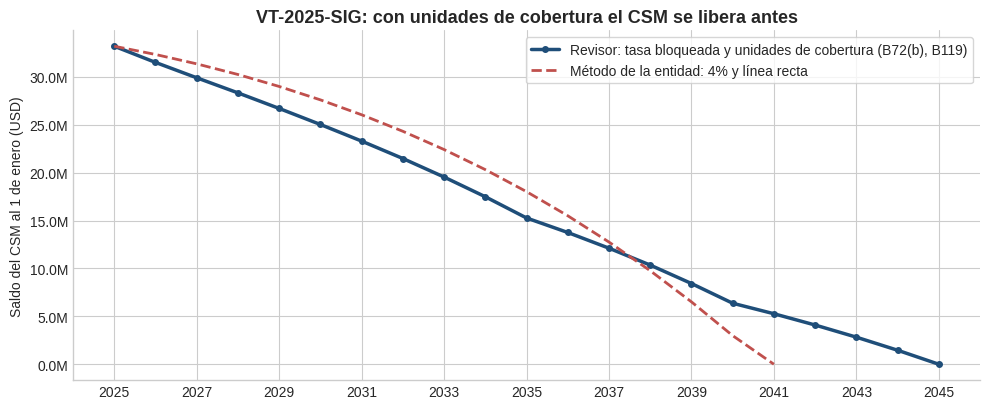

In [18]:
g = big
opening = groups_aud.loc[g, "CSM"]
straight = [opening]
for t in range(T):
    left = avg_term[g] - t
    if left <= 0 or straight[-1] <= 0:
        break
    pre = straight[-1] * 1.04
    straight.append(max(pre - pre / max(left, 1), 0.0))
cu_path = np.r_[opening, sched[g]["saldo final"].to_numpy()]

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(2025 + np.arange(len(cu_path)), cu_path, color=COLORS["primary"], lw=2.5, marker="o", ms=4,
        label="Revisor: tasa bloqueada y unidades de cobertura (B72(b), B119)")
ax.plot(2025 + np.arange(len(straight)), straight, color=COLORS["accent"], lw=2, ls="--",
        label="Método de la entidad: 4% y línea recta")
ax.yaxis.set_major_formatter(musd)
ax.set_title(f"{g}: con unidades de cobertura el CSM se libera antes", fontsize=13, fontweight="bold")
ax.set_xticks(range(2025, 2046, 2))
ax.set_ylabel("Saldo del CSM al 1 de enero (USD)")
ax.legend(frameon=True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

**Hallazgos 3 y 4.** Con unidades de cobertura, la liberación es mayor al principio, aunque la prima sea nivelada: la suma asegurada en vigor baja con cada muerte y cada caducidad. La línea recta ignora esa caída y difiere ganancia que ya se devengó. Además, al usar el plazo promedio, agota el CSM hacia 2041, cuando los contratos a 20 años siguen dando cobertura hasta 2044. La tasa de 4% tampoco es la bloqueada: B72(b) exige las tasas de la fecha de reconocimiento inicial, que para esta cohorte son las de la curva de diciembre de 2024.

## 7. Pasivo por siniestros incurridos (LIC) al 31 de diciembre de 2025

El LIC es la obligación de pagar siniestros ya ocurridos, reportados o no, y los gastos para liquidarlos (Apéndice A, par. 40(b), B65(f)). Se mide con flujos de cumplimiento: valor presente (par. 36) más ajuste por riesgo (par. 37). En vida temporal el monto de cada siniestro es la suma asegurada, así que la incertidumbre no está en cuánto vale un siniestro reportado, sino en cuántas muertes ocurridas todavía no se reportan (IBNR).

### 7.1 Triángulo de desarrollo del reporte

Armo un triángulo trimestral: filas = trimestre de la muerte, columnas = trimestres transcurridos hasta el reporte, valores = suma asegurada reportada acumulada.

In [19]:
def quarter(d):
    return (d.dt.year - 2023) * 4 + d.dt.quarter - 1


register["aq"] = quarter(register["death_date"])
register["dq"] = quarter(register["report_date"]) - register["aq"]
I = 12
J = int(register["dq"].max()) + 1
labels = [f"{2023 + k // 4}T{k % 4 + 1}" for k in range(I)]

inc = register.pivot_table(index="aq", columns="dq", values="amount", aggfunc="sum").reindex(index=range(I), columns=range(J)).fillna(0.0)
observed = (np.arange(I)[:, None] + np.arange(J)[None, :]) <= I - 1
X = np.where(observed, inc.to_numpy(), np.nan)          # incrementales observados
C = np.where(observed, np.nancumsum(X, axis=1), np.nan)  # acumulados

(pd.DataFrame(C / 1e3, index=labels, columns=[f"+{j}" for j in range(J)])
 .style.format("{:,.0f}", na_rep="").set_caption("Suma asegurada reportada acumulada (miles de USD)"))

,+0,+1,+2,+3,+4,+5,+6,+7
2023T1,"1,350","1,945","2,050","2,050","2,155","2,155","2,155","2,155"
2023T2,"1,095","1,655","1,655","1,655","1,655","1,655","1,655","1,785"
2023T3,"1,860","3,370","3,445","3,520","3,520","3,520","3,645","3,645"
2023T4,"1,705","2,190","2,615","2,745","2,745","2,745","2,745","2,745"
2024T1,"3,060","4,000","4,250","4,400","4,500","4,580","4,580","4,580"
2024T2,"4,400","5,470","5,820","5,960","5,960","5,960","5,960",
2024T3,"3,510","4,345","4,400","4,400","4,400","4,400",,
2024T4,"2,120","3,960","4,360","4,360","4,360",,,
2025T1,"5,530","7,450","7,825","7,915",,,,
2025T2,"5,635","7,490","7,565",,,,,


### 7.2 Chain Ladder y Bornhuetter-Ferguson

Chain Ladder proyecta cada trimestre con los factores de desarrollo observados. Funciona bien en los trimestres maduros, pero en el último trimestre todo depende de lo poco que ya se reportó. Bornhuetter-Ferguson (1972) parte de los siniestros esperados según la mortalidad de mejor estimación y solo usa el patrón de reporte para estimar la parte que falta. En vida esa expectativa es sólida, porque viene de la tabla y de la cartera en vigor. Por eso selecciono Bornhuetter-Ferguson para los dos trimestres más recientes y Chain Ladder para el resto.

In [20]:
def cl_factors(C):
    f = np.ones(C.shape[1] - 1)
    for j in range(C.shape[1] - 1):
        rows = ~np.isnan(C[:, j + 1])
        f[j] = C[rows, j + 1].sum() / C[rows, j].sum()
    return f


f = cl_factors(C)
last = observed.sum(1) - 1
latest = C[np.arange(I), last]
cdf = np.array([np.prod(f[d:]) for d in last])
ibnr_cl = latest * (cdf - 1)

expected_q = []                                       # siniestros esperados por trimestre (mejor estimación)
for year in (2023, 2024, 2025):
    p = exposed_at_start(year)
    att = p["issue_age"] + year - p["cohort"]
    q = cso_q(p["sex"], att) * be_factor(att) * (1 - IMPROVEMENT) ** (year - 2025)
    expected_q += [(q * p["sum_insured"]).sum() / 4] * 4
expected_q = np.array(expected_q)
ibnr_bf = expected_q * (1 - 1 / cdf)
ibnr_sel = np.where(np.arange(I) >= I - 2, ibnr_bf, ibnr_cl)

lic_tab = pd.DataFrame({"reportado": latest, "% reportado": 1 / cdf, "esperado (BE)": expected_q,
                        "IBNR Chain Ladder": ibnr_cl, "IBNR Bornhuetter-Ferguson": ibnr_bf, "IBNR seleccionado": ibnr_sel}, index=labels)
lic_tab.loc["Total"] = lic_tab.sum()
lic_tab.loc["Total", "% reportado"] = np.nan
print("Factores de desarrollo:", np.round(f, 4))
money(lic_tab.tail(6), extra={"% reportado": "{:.1%}"})

Factores de desarrollo: [1.3624 1.0504 1.0161 1.007  1.0032 1.0061 1.0088]


,reportado,% reportado,esperado (BE),IBNR Chain Ladder,IBNR Bornhuetter-Ferguson,IBNR seleccionado
2024T4,"4,360,000",98.2%,"5,003,369","79,216","89,283","79,216"
2025T1,"7,915,000",97.5%,"7,451,981","200,597","184,194","200,597"
2025T2,"7,565,000",96.0%,"7,451,981","316,320","299,088","316,320"
2025T3,"6,625,000",91.4%,"7,451,981","624,794","642,219","642,219"
2025T4,"5,165,000",67.1%,"7,451,981","2,535,197","2,453,475","2,453,475"
Total,"56,900,000",—,"59,933,351","3,874,161","3,785,399","3,809,863"


### 7.3 Ajuste por riesgo con bootstrap de Chain Ladder

Para medir la incertidumbre del IBNR uso el bootstrap del modelo Poisson sobredisperso (ODP) de England y Verrall (1999, 2002), en la versión práctica de Shapland (2016):

1. Ajusto Chain Ladder y obtengo los incrementales esperados hacia atrás desde la última diagonal.
2. Calculo los residuos de Pearson, $r = (X - m)/\sqrt{m}$, los ajusto por grados de libertad y estimo la dispersión $\phi$.
3. En cada simulación remuestreo los residuos, armo un triángulo ficticio, vuelvo a estimar los factores y proyecto el futuro.
4. Agrego la varianza del proceso con una distribución gamma de media $\mu$ y varianza $\phi\mu$.

El ajuste por riesgo es el percentil 75 menos la media, en proporción al IBNR seleccionado. El nivel de confianza (75%) se revela según el par. 119.

φ = 136,038 | IBNR Chain Ladder = 3,874,161 | media bootstrap = 4,064,973 | CV = 26.1%
Percentil 75 = 4,747,268 | (P75 / media − 1) = 16.8% | ajuste por riesgo del LIC = 639,476
El IBNR de la entidad (USD 1,862,995) está en el percentil 1% de la distribución.


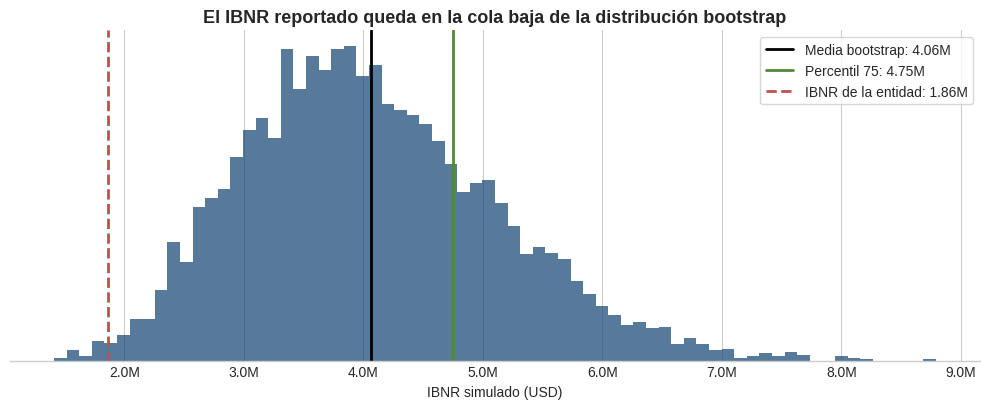

In [21]:
def odp_bootstrap(X, observed, n_sims=5000, seed=2026, process=True):
    I, J = X.shape
    C = np.where(observed, np.nancumsum(X, axis=1), np.nan)
    f = cl_factors(C)
    last = observed.sum(1) - 1
    fit = np.full((I, J), np.nan)                       # acumulados ajustados hacia atrás
    for i in range(I):
        fit[i, last[i]] = C[i, last[i]]
        for j in range(last[i] - 1, -1, -1):
            fit[i, j] = fit[i, j + 1] / f[j]
    m = np.diff(np.hstack([np.zeros((I, 1)), fit]), axis=1)
    use = observed & (m > 0)
    r = np.where(use, (np.nan_to_num(X) - m) / np.sqrt(np.where(use, m, 1.0)), np.nan)
    n, p = use.sum(), I + J - 1
    phi = np.nansum(r ** 2) / (n - p)
    pool = (r * np.sqrt(n / (n - p)))[use & (np.abs(r) > 1e-9)]   # sin residuos estructurales cero

    rng = np.random.default_rng(seed)
    sims = np.empty(n_sims)
    for b in range(n_sims):
        Xb = np.where(use, m + rng.choice(pool, size=(I, J)) * np.sqrt(np.where(use, m, 0.0)), X)
        Cb = np.where(observed, np.nancumsum(Xb, axis=1), np.nan)
        fb = cl_factors(Cb)
        c = Cb[np.arange(I), last]
        total = 0.0
        for j in range(J - 1):
            grow = last <= j
            mu = np.where(grow, c * (fb[j] - 1), 0.0)
            c = np.where(grow, c * fb[j], c)
            mu = mu[mu > 0]
            total += rng.gamma(mu / phi, phi).sum() if process else mu.sum()   # varianza del proceso
        sims[b] = total
    return sims, phi


sims, phi = odp_bootstrap(X, observed)
p75 = np.percentile(sims, 75)
ra_factor = p75 / sims.mean() - 1
ibnr_total = ibnr_sel.sum()
ra_lic = ra_factor * ibnr_total
mgmt_lic = mgmt["lic_2025"]
pct_mgmt = (sims <= mgmt_lic["ibnr"]).mean()

print(f"φ = {phi:,.0f} | IBNR Chain Ladder = {ibnr_cl.sum():,.0f} | media bootstrap = {sims.mean():,.0f} | CV = {sims.std() / sims.mean():.1%}")
print(f"Percentil 75 = {p75:,.0f} | (P75 / media − 1) = {ra_factor:.1%} | ajuste por riesgo del LIC = {ra_lic:,.0f}")
print(f"El IBNR de la entidad (USD {mgmt_lic['ibnr']:,.0f}) está en el percentil {pct_mgmt:.0%} de la distribución.")

fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(sims, bins=70, color=COLORS["primary"], alpha=0.75)
for val, lab, col, ls in [(sims.mean(), "Media bootstrap", "black", "-"), (p75, "Percentil 75", COLORS["green"], "-"),
                          (mgmt_lic["ibnr"], "IBNR de la entidad", COLORS["accent"], "--")]:
    ax.axvline(val, color=col, lw=2, ls=ls, label=f"{lab}: {val / 1e6:,.2f}M")
ax.xaxis.set_major_formatter(musd)
ax.set_title("El IBNR reportado queda en la cola baja de la distribución bootstrap", fontsize=13, fontweight="bold")
ax.set_xlabel("IBNR simulado (USD)")
ax.set_yticks([])
ax.legend(frameon=True)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

### 7.4 Segunda herramienta: `chainladder`

Un revisor no se queda con su propio código sin contrastarlo. Repito el cálculo con `chainladder`, un paquete de código abierto de reservas actuariales. El IBNR de Chain Ladder debe coincidir exactamente. El remuestreo de `chainladder` no agrega la varianza del proceso, así que lo comparo con mi bootstrap sin ese paso. El error de predicción total lo comparo con el de Mack (1993), que es un modelo distinto pero mide lo mismo.

In [22]:
import chainladder as cl

warnings.simplefilter("ignore")   # avisos internos del paquete (ajuste de cola y matriz hat)
tri_df = pd.DataFrame({"origin": register["death_date"].dt.to_period("Q").dt.start_time,
                       "valuation": register["report_date"].dt.to_period("Q").dt.end_time.dt.normalize(),
                       "amount": register["amount"]})
tri = cl.Triangle(tri_df, origin="origin", development="valuation", columns="amount", cumulative=False).incr_to_cum()
mack = cl.MackChainladder().fit(tri)
boot = cl.BootstrapODPSample(n_sims=5000, random_state=2026).fit(tri)
boot_ibnr = cl.Chainladder().fit(boot.resampled_triangles_).ibnr_.sum("origin").values.ravel()
sims_param, _ = odp_bootstrap(X, observed, process=False)   # mismo bootstrap, sin varianza del proceso

check = pd.DataFrame({
    "Revisor (código propio)": [ibnr_cl.sum(), sims_param.mean(), sims_param.std(), sims.std()],
    "chainladder": [float(mack.ibnr_.sum()), boot_ibnr.mean(), boot_ibnr.std(),
                    float(mack.total_mack_std_err_.values.ravel()[0])]},
    index=["IBNR Chain Ladder", "Bootstrap, solo parámetros: media", "Bootstrap, solo parámetros: desviación",
           "Error de predicción total (revisor: bootstrap; chainladder: Mack)"])
check["diferencia %"] = check["chainladder"] / check["Revisor (código propio)"] - 1
money(check, extra={"diferencia %": "{:+.1%}"})

,Revisor (código propio),chainladder,diferencia %
IBNR Chain Ladder,"3,874,161","3,874,161",+0.0%
"Bootstrap, solo parámetros: media","4,051,364","3,881,934",-4.2%
"Bootstrap, solo parámetros: desviación","759,532","768,483",+1.2%
Error de predicción total (revisor: bootstrap; chainladder: Mack),"1,059,554","1,275,575",+20.4%


Las diferencias que quedan vienen de detalles de implementación, como el ajuste de los residuos por grados de libertad y el tratamiento de los residuos estructurales en cero, y en el caso de Mack de que es un modelo distinto. Con un triángulo tan corto, diferencias de este tamaño son normales. Ninguna cambia la conclusión: el IBNR de la entidad queda por debajo de lo que sostienen los datos.

### 7.5 Gastos de liquidación, descuento y LIC total

- **Gastos de liquidación (B65(f)):** USD 200 por siniestro, inflados a 2026, para los pendientes y para el número estimado de muertes no reportadas.
- **Descuento (par. 36):** con la curva de diciembre de 2025, según el tiempo esperado hasta el pago. El par. 59(b), que permite no descontar, solo aplica al enfoque de asignación de primas (PAA), no a este modelo. Aunque el efecto sea pequeño, se calcula y se documenta.

In [23]:
settle = register[paid].assign(days=lambda d: (d["payment_date"] - d["report_date"]).dt.days).groupby("contestable")["days"].mean()
elapsed = (pd.Timestamp("2025-12-31") - pending["report_date"]).dt.days
days_left = np.maximum(pending["contestable"].map(settle) - elapsed, 15)

months = np.r_[0, CURVE_2025.index.to_numpy()]
dfs_m = np.r_[1.0, CURVE_2025.to_numpy()]
df_rbns = np.interp(days_left / 30.4, months, dfs_m)
report_lag = (register["report_date"] - register["death_date"]).dt.days
ibnr_days = report_lag[register["dq"] > 0].mean() / 2 + settle.mean()   # supuesto documentado
df_ibnr = np.interp(ibnr_days / 30.4, months, dfs_m)

avg_claim = register.loc[register["death_date"].dt.year == 2025, "amount"].mean()
n_ibnr = ibnr_total / avg_claim
handling = (len(pending) + n_ibnr) * EXP["claim_handling_per_claim"] * (1 + EXP["inflation"])
rbns = pending["amount"].sum()
discount = -((pending["amount"] * (1 - df_rbns)).sum() + ibnr_total * (1 - df_ibnr))

auditor_lic = pd.Series({"rbns": rbns, "ibnr": ibnr_total, "claim_handling": handling,
                         "discounting": discount, "risk_adjustment": ra_lic})
auditor_lic["total"] = auditor_lic.sum()
names = {"rbns": "Siniestros reportados pendientes (RBNS)", "ibnr": "IBNR", "claim_handling": "Gastos de liquidación (B65(f))",
         "discounting": "Efecto del descuento (par. 36)", "risk_adjustment": "Ajuste por riesgo (par. 37)", "total": "LIC total"}
lic_cmp = pd.DataFrame({"Entidad": pd.Series(mgmt_lic), "Revisor": auditor_lic}).reindex(list(names)).rename(index=names)
lic_cmp["Diferencia"] = lic_cmp["Revisor"] - lic_cmp["Entidad"]
money(lic_cmp)

,Entidad,Revisor,Diferencia
Siniestros reportados pendientes (RBNS),"4,240,000","5,035,000","795,000"
IBNR,"1,862,995","3,809,863","1,946,868"
Gastos de liquidación (B65(f)),0,"14,472","14,472"
Efecto del descuento (par. 36),0,"-61,555","-61,555"
Ajuste por riesgo (par. 37),0,"639,476","639,476"
LIC total,"6,102,995","9,437,256","3,334,261"


### 7.6 Evidencia posterior al cierre (NIA 540, párr. 18(a))

Los siniestros reportados entre el 1 de enero y el 28 de febrero de 2026 por muertes de 2025 o antes son una comprobación directa del IBNR. A diferencia del ejemplo de la tormenta de B55, estas muertes ocurrieron antes del cierre: informan sobre condiciones que ya existían a esa fecha (NIC 10). No son todo el IBNR, porque algunos siniestros se reportarán después de la fecha del informe, pero dan un piso.

In [24]:
late = after_close["amount"].sum()
print(f"Reportado entre el 1-ene y el 28-feb-2026 por muertes hasta 2025: {len(after_close)} siniestros, USD {late:,.0f}")
print(f"Cobertura del IBNR recalculado:    {late / ibnr_total:.0%}")
print(f"Cobertura del IBNR de la entidad:  {late / mgmt_lic['ibnr']:.0%}")

Reportado entre el 1-ene y el 28-feb-2026 por muertes hasta 2025: 21 siniestros, USD 2,960,000
Cobertura del IBNR recalculado:    78%
Cobertura del IBNR de la entidad:  159%


## 8. Resumen de hallazgos

En un encargo real, cada diferencia se acumula y se evalúa contra la materialidad (NIA 450), y la falla en el corte del listado se comunica como deficiencia de control (NIA 265). Las cifras de esta tabla son del ejercicio y sirven para mostrar el tipo de conclusión.

In [25]:
lc_aud = groups_aud["componente_pérdida"].sum()
findings = pd.DataFrame([
    ["1. Agrupación por canal compensa contratos onerosos", "16–17, 47", "Componente de pérdida no reconocido (resultado 2025)", lc_aud],
    ["2. Ajuste por riesgo sin caducidad ni gastos", "37, B86", "Ajuste por riesgo (el CSM baja en el mismo monto)", recon.loc["Ajuste por riesgo", "(b) Ajuste con caducidad y gastos (B86)"]],
    ["3. Intereses del CSM a 4% y no a tasa bloqueada", "44(b), B72(b)", "CSM al 31-dic", csm_bridge.iloc[2]],
    ["4. Liberación del CSM en línea recta", "44(e), B119", "CSM al 31-dic (ingreso de 2025 diferido)", csm_bridge.iloc[3]],
    ["5. Listado de pendientes cortado el 19-dic", "40(b)", "LIC: siniestros pendientes", lic_cmp.loc[names["rbns"], "Diferencia"]],
    ["6. IBNR como 25% de los esperados del cuarto trimestre", "33, 40(b)", "LIC: IBNR", lic_cmp.loc[names["ibnr"], "Diferencia"]],
    ["7. LIC sin gastos de liquidación, descuento ni ajuste por riesgo", "36, 37, B65(f)", "LIC: otros componentes",
     lic_cmp.loc[[names["claim_handling"], names["discounting"], names["risk_adjustment"]], "Diferencia"].sum()],
], columns=["Hallazgo", "IFRS 17", "Partida afectada", "Efecto (USD)"])

sens = project(c25, DF_LOCKED, mort=1.01).fcf.sum() - base.fcf.sum()
print(f"Sensibilidad de referencia: cada punto porcentual adicional de mortalidad aumenta los flujos de cumplimiento "
      f"de la cohorte 2025 en USD {sens:,.0f}. Por eso la prueba A/E de la sección 2.1 es parte central de la revisión.")
print(f"LIC: la entidad reporta USD {mgmt_lic['total']:,.0f} y el recálculo da USD {auditor_lic['total']:,.0f} "
      f"({auditor_lic['total'] / mgmt_lic['total'] - 1:+.0%}).")
print("Signo: + aumenta la partida; − la reduce.")
money(findings).hide()

Sensibilidad de referencia: cada punto porcentual adicional de mortalidad aumenta los flujos de cumplimiento de la cohorte 2025 en USD 1,122,445. Por eso la prueba A/E de la sección 2.1 es parte central de la revisión.
LIC: la entidad reporta USD 6,102,995 y el recálculo da USD 9,437,256 (+55%).
Signo: + aumenta la partida; − la reduce.


Hallazgo,IFRS 17,Partida afectada,Efecto (USD)
1. Agrupación por canal compensa contratos onerosos,"16–17, 47",Componente de pérdida no reconocido (resultado 2025),"910,766"
2. Ajuste por riesgo sin caducidad ni gastos,"37, B86",Ajuste por riesgo (el CSM baja en el mismo monto),"599,518"
3. Intereses del CSM a 4% y no a tasa bloqueada,"44(b), B72(b)",CSM al 31-dic,"212,159"
4. Liberación del CSM en línea recta,"44(e), B119",CSM al 31-dic (ingreso de 2025 diferido),"-1,108,404"
5. Listado de pendientes cortado el 19-dic,40(b),LIC: siniestros pendientes,"795,000"
6. IBNR como 25% de los esperados del cuarto trimestre,"33, 40(b)",LIC: IBNR,"1,946,868"
"7. LIC sin gastos de liquidación, descuento ni ajuste por riesgo","36, 37, B65(f)",LIC: otros componentes,"592,393"


**Cómo leer el resumen.**

- **Lo más importante: el hallazgo 1.** La entidad no reconoce una pérdida que la norma exige reconocer de inmediato (par. 47).
- **Hallazgos 2 a 4.** Son diferencias entre la política escrita y lo que el modelo hace en realidad. Es un patrón frecuente: la política está bien redactada, pero nadie concilió el código contra ella.
- **Hallazgos 5 a 7.** Subestiman el LIC. La evidencia posterior al cierre confirma que el IBNR de la entidad era insuficiente.

## 9. Fuentes

- IFRS Foundation. *IFRS 17 Insurance Contracts* (incluye las modificaciones de junio de 2020). Párrafos citados en cada sección.
- EY (2024). *Reporting under IFRS 17 and IFRS 9: Observations from year-end 2023 financial statements published by insurers*.
- Reback (2017). IFRS 17 Risk Adjustment Confidence Level Disclosure. *The Financial Reporter*, Society of Actuaries, diciembre de 2017.
- Unión Europea. *Directiva (UE) 2025/2*, que modifica Solvencia II (tasa de costo de capital de 4,75%).
- IAASB. *NIA 540 (Revisada), Auditoría de estimaciones contables y de la información relacionada a revelar*; *NIA 450*; *NIA 265*.
- Society of Actuaries. *1980 CSO*, tablas 42 (hombres, ANB) y 36 (mujeres, ANB), en mort.soa.org.
- Unión Europea. *Reglamento Delegado (UE) 2015/35* (Solvencia II), art. 39 (tasa de costo de capital), 136 a 142 (submódulo de suscripción de vida y sus correlaciones).
- International Actuarial Association (2018). *Risk Adjustments for Insurance Contracts under IFRS 17*.
- Longley-Cook, L. H. (1962). An Introduction to Credibility Theory. *Proceedings of the Casualty Actuarial Society*, 49.
- Bornhuetter, R. L. y Ferguson, R. E. (1972). The Actuary and IBNR. *Proceedings of the Casualty Actuarial Society*, 59.
- Mack, T. (1993). Distribution-free calculation of the standard error of chain ladder reserve estimates. *ASTIN Bulletin*, 23(2).
- England, P. y Verrall, R. (1999). Analytic and bootstrap estimates of prediction errors in claims reserving. *Insurance: Mathematics and Economics*, 25(3).
- England, P. y Verrall, R. (2002). Stochastic claims reserving in general insurance. *British Actuarial Journal*, 8(3) (Institute and Faculty of Actuaries).
- Shapland, M. R. (2016). *Using the ODP Bootstrap Model: A Practitioner's Guide*. CAS Monograph Series No. 4.
- U.S. Department of the Treasury. *HQM Corporate Bond Yield Curve*, curvas de fin de mes (ver notebook 01).
- `chainladder-python`, paquete de código abierto de reservas actuariales.